# ЛЦТ 2026 · Фалькон Тех — Vehicle ReID · EDA

**Task.** Open-set vehicle re-identification. For every `test_query` crop rank all `test_gallery` crops
(submit top-10), save embeddings, and run a *refusal mode* that returns nothing when no confident match exists.

**How it is scored (from the ТЗ).** mAP on a hidden test part, with **same-camera matches excluded** (45%);
Rank-1/5 as extra columns; refusal mode is scored by F1 + TNR at a team-chosen threshold (10%); speed and weights ≤ 2 GB (20%).

**Plan.** Every section ends with *so what* for validation or modelling.

1. Integrity · 2. Identity & camera structure · 3. BBox geometry · 4. Image quality · 5. Train↔test shift (adversarial validation)
6. Similarity structure & duplicates · 7. How the test split was built · 8. Scenes & camera bias · 9. Attributes (CLIP zero-shot)
10. Zero-shot retrieval baseline & error analysis · 11. Refusal-mode simulation · 12. Takeaways

Heavy features (image stats, DINOv2 / CLIP embeddings) are computed once by `eda/extract_features.py` → `eda/cache/`.

In [1]:
import json
from itertools import combinations
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.sparse.csgraph import connected_components
from scipy.stats import ks_2samp, spearmanr

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "eda" else Path.cwd().resolve()
DATA, CACHE = ROOT / "BIG_DATA" / "dataset", ROOT / "eda" / "cache"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 11})
pd.set_option("display.width", 200, "display.max_columns", 50, "display.precision", 3)
SPLITS = ["train", "query", "gallery"]
PAL = dict(zip(SPLITS, sns.color_palette("deep", 3)))

M = pd.read_parquet(CACHE / "meta_stats.parquet")
E_dino = np.load(CACHE / "emb_dino_crop.npy").astype(np.float32)
E_clip = np.load(CACHE / "emb_clip_crop.npy").astype(np.float32)
E_scene = np.load(CACHE / "emb_dino_scene.npy").astype(np.float32)

# derived columns
M["area_k"] = M.w * M.h / 1e3
M["aspect"] = M.w / M.h
M["cx"], M["cy"] = (M.x + M.w / 2) / M.W, (M.y + M.h / 2) / M.H
M["truncated"] = (M.x <= 0) | (M.y <= 0) | (M.x + M.w >= M.W) | (M.y + M.h >= M.H)
M["log_blur"] = np.log10(M.crop_blur + 1)
M["is_test"] = M.split.ne("train")

it = np.flatnonzero(M.split.eq("train"))
qi, gi = np.flatnonzero(M.split.eq("query")), np.flatnonzero(M.split.eq("gallery"))
te = np.flatnonzero(M.is_test)
assert (it == np.arange(len(it))).all()  # train rows come first -> train positions == M positions
tr = M.iloc[it]
pid, cam = tr.vehicle_id.to_numpy(int), tr.camera_id.to_numpy(int)
print(M.split.value_counts().reindex(SPLITS).to_dict(), E_dino.shape, E_clip.shape, E_scene.shape)


def l2n(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)


def crop(i, max_h=200):
    r = M.iloc[i]
    im = cv2.imread(str(DATA / "images" / f"{r.image_id}.jpg"))[..., ::-1]
    c = im[max(r.y, 0): r.y + r.h, max(r.x, 0): r.x + r.w]
    return cv2.resize(c, (max(1, round(c.shape[1] * max_h / c.shape[0])), max_h)) if c.shape[0] > max_h else c


def show_crops(idx, titles=None, colors=None, ncol=8, size=2.3, suptitle=None):
    idx = list(idx)
    nrow = int(np.ceil(len(idx) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size * 0.8), squeeze=False)
    for a in axes.flat:
        a.axis("off")
    for k, i in enumerate(idx):
        a = axes.flat[k]
        a.imshow(crop(i))
        if titles is not None:
            a.set_title(titles[k], fontsize=8, color=colors[k] if colors is not None else "black")
    if suptitle:
        fig.suptitle(suptitle, y=1.0)
    plt.tight_layout()
    plt.show()


def kde_grid(cols, ncol=3, **kw):
    fig, axes = plt.subplots(int(np.ceil(len(cols) / ncol)), ncol, figsize=(6 * ncol, 3.6 * np.ceil(len(cols) / ncol)))
    for c, a in zip(cols, axes.flat):
        sns.kdeplot(data=M, x=c, hue="split", hue_order=SPLITS, palette=PAL, common_norm=False,
                    fill=True, alpha=0.12, ax=a, **kw)
    plt.tight_layout()
    plt.show()


def shift_table(cols):
    """Train vs test (query+gallery): medians, KS statistic, univariate adversarial AUC."""
    from sklearn.metrics import roc_auc_score
    rows = {}
    for c in cols:
        a, b = M.loc[~M.is_test, c].astype(float), M.loc[M.is_test, c].astype(float)
        auc = roc_auc_score(M.is_test, M[c].astype(float))
        rows[c] = {"train median": a.median(), "test median": b.median(),
                   "KS": ks_2samp(a, b).statistic, "adv AUC": max(auc, 1 - auc)}
    return pd.DataFrame(rows).T

{'train': 9556, 'query': 1110, 'gallery': 750} (11416, 768) (11416, 512) (11416, 768)


## 1. Integrity checks

In [2]:
on_disk = {p.stem for p in (DATA / "images").glob("*.jpg")}
headers = {f: pd.read_csv(DATA / f, nrows=0).columns.tolist() for f in ["train.csv", "test_query.csv", "test_gallery.csv"]}
pd.Series({
    "rows train / query / gallery": M.split.value_counts().reindex(SPLITS).tolist(),
    "images on disk": len(on_disk),
    "csv rows <-> image files 1:1": on_disk == set(M.image_id) and not M.image_id.duplicated().any(),
    "max boxes per image": M.groupby("image_id").size().max(),
    "NaNs in boxes": int(M[["x", "y", "w", "h"]].isna().sum().sum()),
    "frame sizes (W, H)": M[["W", "H"]].drop_duplicates().values.tolist(),
    "boxes outside frame": int(((M.x < 0) | (M.y < 0) | (M.x + M.w > M.W) | (M.y + M.h > M.H)).sum()),
    "min crop w / h, px": (M.w.min(), M.h.min()),
    "byte-identical files (md5)": int(M.md5.duplicated(keep=False).sum()),
    "train columns": headers["train.csv"],
    "query / gallery columns": headers["test_query.csv"],
}).to_frame("value")

,value
rows train / query / gallery,"[9556, 1110, 750]"
images on disk,11416
csv rows <-> image files 1:1,True
max boxes per image,1
NaNs in boxes,0
"frame sizes (W, H)","[[1920, 1080]]"
boxes outside frame,0
"min crop w / h, px","(151, 147)"
byte-identical files (md5),22
train columns,"[image_id, x, y, w, h, vehicle_id, camera_id]"


Byte-identical files stored under different `image_id`s — same frame, different box (a second vehicle in that frame):

In [3]:
dup = M[M.md5.duplicated(keep=False)].sort_values("md5")
dup[["md5", "split", "row", "vehicle_id", "camera_id", "x", "y", "w", "h"]].assign(md5=dup.md5.str[:8])

,md5,split,row,vehicle_id,camera_id,x,y,w,h
5049,002956b7,train,5049,29.0,39.0,93,47,668,480
5304,002956b7,train,5304,714.0,39.0,652,382,781,596
8501,2e4cd943,train,8501,259.0,89.0,177,446,643,413
9437,2e4cd943,train,9437,452.0,89.0,1153,405,693,412
2427,440d8a44,train,2427,904.0,90.0,1171,596,584,413
9526,440d8a44,train,9526,555.0,90.0,610,463,623,495
6268,4e1c82d4,train,6268,1473.0,90.0,486,451,753,440
7380,4e1c82d4,train,7380,1204.0,90.0,0,535,635,390
2429,545a2f4b,train,2429,904.0,89.0,80,455,597,417
9529,545a2f4b,train,9529,555.0,89.0,677,304,623,546


**Findings.**
* Clean annotations: 11 416 frames ↔ 11 416 csv rows, one box per row, all frames 1920×1080, no box outside the frame,
  smallest crop 151×147 px — enough detail for 224–320 px model inputs.
* `train.csv` contains **`camera_id`**, although the ТЗ says camera ids are withheld; the test files don't have it.
  Very useful for validation and camera-aware training — confirm with the organisers that it may be used.
* 11 frames are stored twice with different boxes (two vehicles in one frame): 9 pairs train↔train,
  **1 pair train↔gallery** (a test vehicle is visible in a train frame) and 1 pair query↔gallery (two *different* test
  vehicles with an identical background — a hard same-camera negative). Tiny, but worth knowing.

## 2. Identity & camera structure (train)

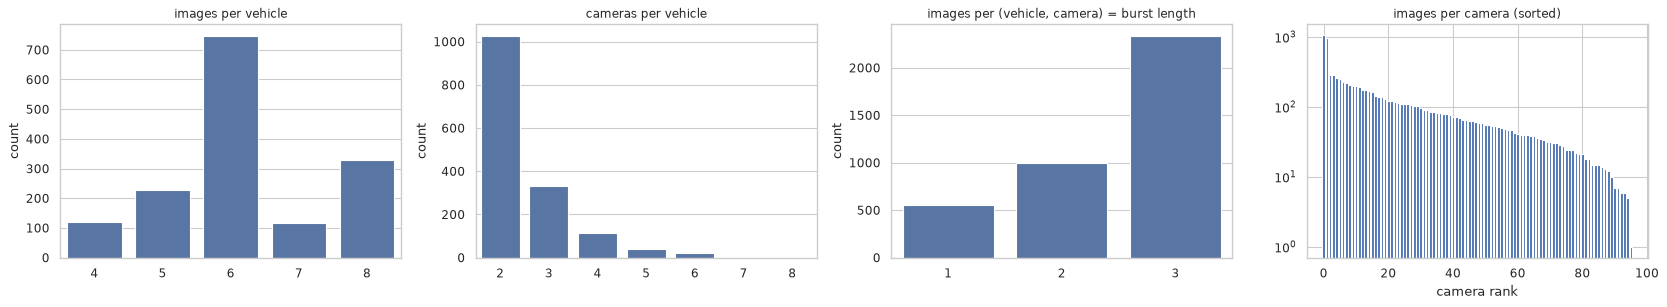

1541 vehicles, 96 cameras, 3884 (vehicle, camera) groups
top-2 cameras hold 21.3% of train images; 15 cameras have < 20 images


camera_id,90.0,89.0,43.0,82.0,6.0,12.0,51.0,33.0,85.0,19.0
n_img,1069,969,287,286,256,251,229,223,208,200
n_id,397,350,112,114,107,103,94,91,89,80


In [4]:
per_id = tr.groupby("vehicle_id").agg(n_img=("image_id", "size"), n_cam=("camera_id", "nunique"))
per_idcam = tr.groupby(["vehicle_id", "camera_id"]).size()
per_cam = (tr.groupby("camera_id").agg(n_img=("image_id", "size"), n_id=("vehicle_id", "nunique"))
           .sort_values("n_img", ascending=False))

fig, ax = plt.subplots(1, 4, figsize=(21, 4))
sns.countplot(x=per_id.n_img, ax=ax[0], color=PAL["train"]).set(title="images per vehicle", xlabel="")
sns.countplot(x=per_id.n_cam, ax=ax[1], color=PAL["train"]).set(title="cameras per vehicle", xlabel="")
sns.countplot(x=per_idcam.to_numpy(), ax=ax[2], color=PAL["train"]).set(title="images per (vehicle, camera) = burst length", xlabel="")
ax[3].bar(range(len(per_cam)), per_cam.n_img, color=PAL["train"])
ax[3].set(yscale="log", title="images per camera (sorted)", xlabel="camera rank")
plt.tight_layout()
plt.show()

print(f"{len(per_id)} vehicles, {len(per_cam)} cameras, {len(per_idcam)} (vehicle, camera) groups")
print(f"top-2 cameras hold {per_cam.n_img.iloc[:2].sum() / len(tr):.1%} of train images; "
      f"{(per_cam.n_img < 20).sum()} cameras have < 20 images")
per_cam.head(10).T

/tmp/ipykernel_1923040/2317672253.py:9: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  order = leaves_list(linkage(np.log1p(C), "average"))


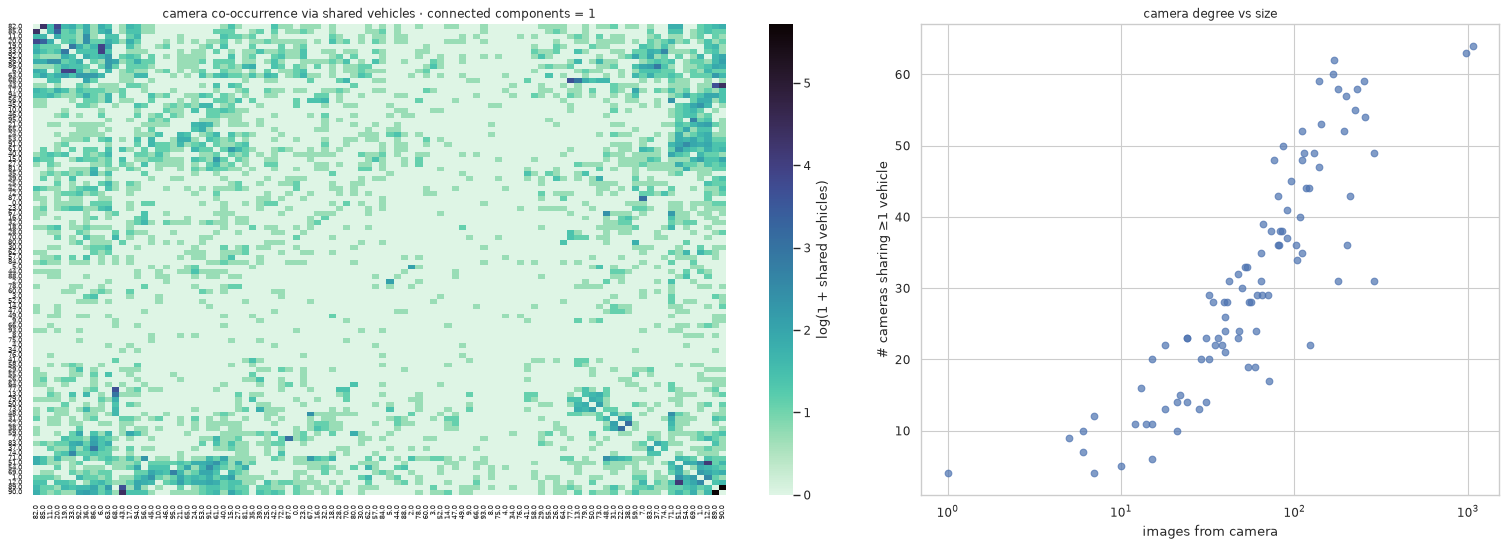

1514 camera pairs share vehicles; top pairs:
89.0  90.0    301
43.0  90.0     81
82.0  85.0     75
12.0  51.0     61
6.0   33.0     52
      19.0     48
20.0  82.0     44
43.0  89.0     38


In [5]:
cams = np.sort(tr.camera_id.unique())
ci = {c: k for k, c in enumerate(cams)}
C = np.zeros((len(cams), len(cams)), int)
for cs in tr.groupby("vehicle_id").camera_id.unique():
    for a, b in combinations(sorted(cs), 2):
        C[ci[a], ci[b]] += 1
        C[ci[b], ci[a]] += 1
n_comp, _ = connected_components(C > 0, directed=False)
order = leaves_list(linkage(np.log1p(C), "average"))

fig, ax = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(np.log1p(C[np.ix_(order, order)]), ax=ax[0], cmap="mako_r", xticklabels=cams[order], yticklabels=cams[order],
            cbar_kws={"label": "log(1 + shared vehicles)"})
ax[0].tick_params(labelsize=6)
ax[0].set_title(f"camera co-occurrence via shared vehicles · connected components = {n_comp}")
ax[1].scatter(per_cam.reindex(cams).n_img, (C > 0).sum(1), alpha=0.7)
ax[1].set(xscale="log", xlabel="images from camera", ylabel="# cameras sharing ≥1 vehicle", title="camera degree vs size")
plt.tight_layout()
plt.show()

pairs = pd.Series({(cams[a], cams[b]): C[a, b] for a, b in zip(*np.triu_indices_from(C, 1)) if C[a, b]}).sort_values(ascending=False)
print(f"{len(pairs)} camera pairs share vehicles; top pairs:\n{pairs.head(8).to_string()}")

**How big is the public test?** Using train ratios:

In [6]:
n_test = len(qi) + len(gi)
pd.Series({
    "test images (query + gallery)": n_test,
    "≈ vehicles  (test images / mean images per vehicle)": n_test / per_id.n_img.mean(),
    "≈ (vehicle, camera) groups  (test images × groups per image)": n_test * len(per_idcam) / len(tr),
    "actual gallery size": len(gi),
    "query / gallery, test": len(qi) / len(gi),
    "(images − groups) / groups, train": (len(tr) - len(per_idcam)) / len(per_idcam),
}).round(2).to_frame("value")

,value
test images (query + gallery),1860.00
≈ vehicles (test images / mean images per vehicle),299.94
"≈ (vehicle, camera) groups (test images × groups per image)",755.99
actual gallery size,750.00
"query / gallery, test",1.48
"(images − groups) / groups, train",1.46


**Findings.**
* 1 541 vehicles · 96 cameras · 4–8 images per vehicle (median 6) · **every vehicle is seen by ≥ 2 cameras**
  (67% by exactly 2 — so most queries have a single cross-camera view to find).
* Frames come in **bursts**: 1–3 near-identical frames per (vehicle, camera); 60% of groups have 3 frames.
* Strong camera imbalance: cameras 90 and 89 hold 21% of all images and share 301 vehicles (likely the same site);
  15 cameras have < 20 images.
* Public test ≈ **300 vehicles**, and the gallery size (750) equals the expected number of (vehicle, camera) groups (756)
  → the gallery is probably one frame per (vehicle, camera); verified in Section 7.

## 3. Bounding-box geometry: train vs test

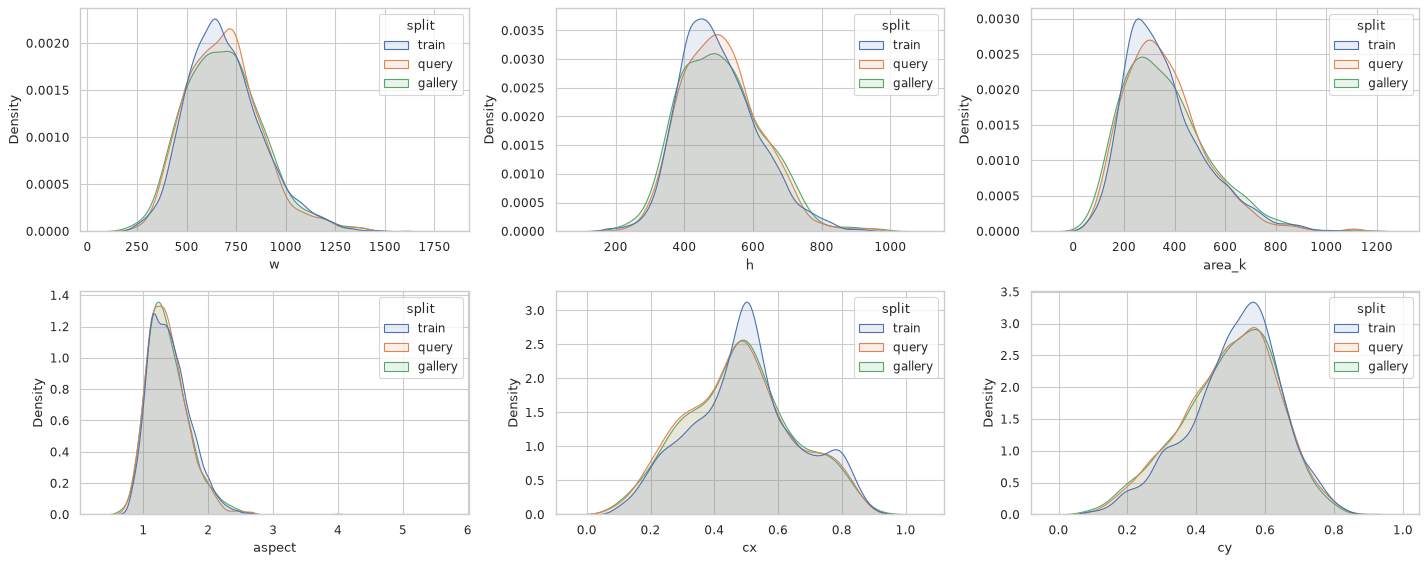

truncated by frame border: {'train': 0.085, 'query': 0.096, 'gallery': 0.103}
extreme aspect ratio (w/h > 3 or < 0.6): {'train': 7, 'query': 1, 'gallery': 0}


,train median,test median,KS,adv AUC
w,669.000,680.500,0.030,0.505
h,485.000,497.000,0.047,0.518
area_k,325.924,336.340,0.034,0.507
aspect,1.357,1.330,0.054,0.527
cx,0.495,0.478,0.064,0.529
cy,0.525,0.509,0.058,0.529
truncated,0.000,0.000,0.013,0.507


In [7]:
GEO = ["w", "h", "area_k", "aspect", "cx", "cy"]
kde_grid(GEO)
print("truncated by frame border:", M.groupby("split").truncated.mean().reindex(SPLITS).round(3).to_dict())
print("extreme aspect ratio (w/h > 3 or < 0.6):", M.groupby("split").aspect.apply(lambda s: int(((s > 3) | (s < 0.6)).sum())).reindex(SPLITS).to_dict())
shift_table(GEO + ["truncated"])

**Findings.** Boxes are large (median ≈ 670×490 px, w/h ≈ 1.35) and roughly centred; 8.5–10% touch the frame border
(truncated vehicles) and a handful are thin strips (w/h up to 4.7, heavily occluded). Train and test geometry are the same
(KS ≤ 0.06, univariate adversarial AUC ≤ 0.53).
→ A landscape input (e.g. 320×240) matches the median aspect better than the classic 256×256 square — worth an ablation;
random-erasing / crop augmentations cover the truncated share.

## 4. Image quality: illumination, colour, blur

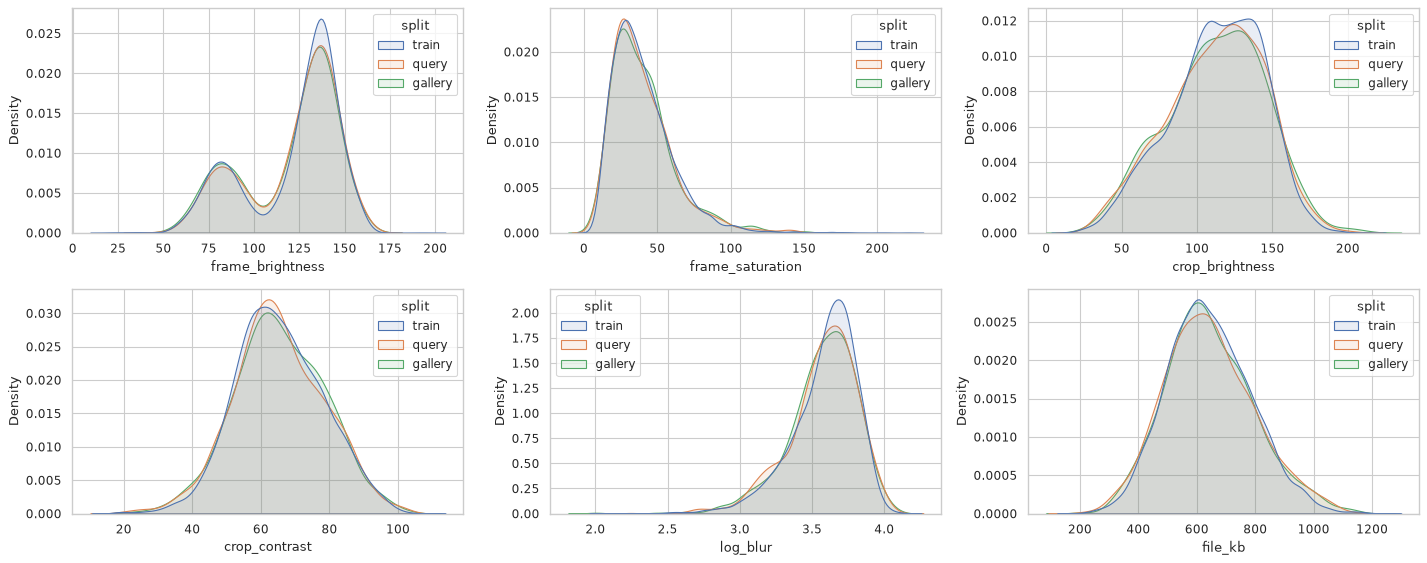

frames darker than 60/255: {'train': 72, 'query': 4, 'gallery': 3}


,train median,test median,KS,adv AUC
frame_brightness,131.098,130.206,0.028,0.511
frame_saturation,35.744,35.290,0.023,0.505
crop_brightness,115.263,114.722,0.027,0.506
crop_contrast,64.590,64.545,0.017,0.501
log_blur,3.626,3.602,0.050,0.518
file_kb,632.666,629.500,0.023,0.503


In [8]:
QUAL = ["frame_brightness", "frame_saturation", "crop_brightness", "crop_contrast", "log_blur", "file_kb"]
kde_grid(QUAL)
print("frames darker than 60/255:", M.groupby("split").frame_brightness.apply(lambda s: int((s < 60).sum())).reindex(SPLITS).to_dict())
shift_table(QUAL)

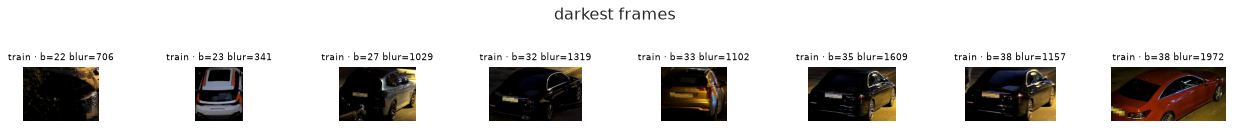

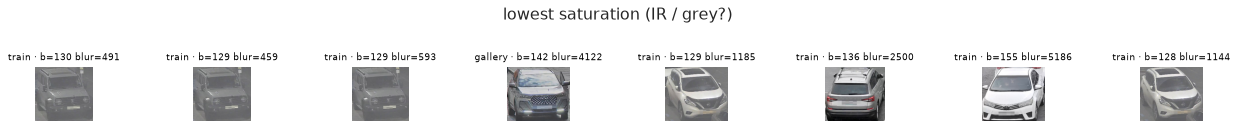

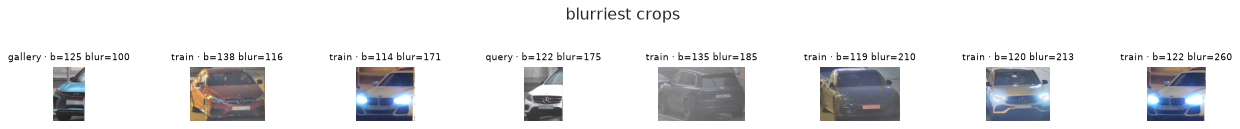

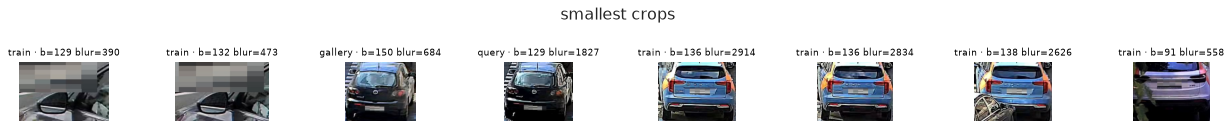

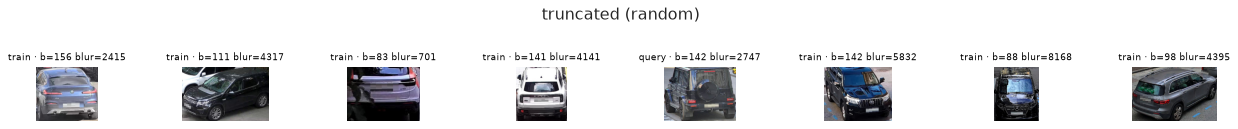

In [9]:
extremes = {
    "darkest frames": M.frame_brightness.nsmallest(8).index,
    "lowest saturation (IR / grey?)": M.frame_saturation.nsmallest(8).index,
    "blurriest crops": M.crop_blur.nsmallest(8).index,
    "smallest crops": M.area_k.nsmallest(8).index,
    "truncated (random)": M[M.truncated].sample(8, random_state=0).index,
}
for name, idx in extremes.items():
    show_crops(idx, titles=[f"{M.split[i]} · b={M.frame_brightness[i]:.0f} blur={M.crop_blur[i]:.0f}" for i in idx],
               suptitle=name, size=2.0)

**Findings.** The data is almost entirely **daylight**: only 72 train / 7 test frames are darker than 60/255
(real night shots with headlights), although the ТЗ mentions different times of day. Low-saturation frames are grey
daytime scenes, not IR. Blur, contrast and file-size distributions match between splits.
→ Night is a rare hard case, not a separate domain: brightness / colour-jitter augmentation is enough.

## 5. Adversarial validation: can a model tell train from test?

Bursts (near-identical consecutive frames) would leak across folds and inflate AUC, so folds are grouped:
train by `vehicle_id`, test by connected components of near-duplicate crops (DINOv2 cos > 0.9).

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

_, te_comp = connected_components((E_dino[te] @ E_dino[te].T) > 0.9, directed=False)
groups = np.empty(len(M), object)
groups[it] = ["tr_" + str(v) for v in pid]
groups[te] = ["te_" + str(c) for c in te_comp]
y = M.is_test.to_numpy(int)
cv = StratifiedGroupKFold(5, shuffle=True, random_state=0)

adv = {}
adv["bbox + quality stats (GBM)"] = cross_val_predict(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05),
                                                      M[GEO + QUAL].to_numpy(float), y, groups=groups, cv=cv, method="predict_proba")[:, 1]
for name, E in {"DINOv2 crop embedding (LogReg)": E_dino, "CLIP crop embedding (LogReg)": E_clip,
                "DINOv2 scene embedding (LogReg)": E_scene}.items():
    adv[name] = cross_val_predict(LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced"), E, y,
                                  groups=groups, cv=cv, method="predict_proba")[:, 1]
pd.Series({k: roc_auc_score(y, p) for k, p in adv.items()}).round(3).to_frame("adversarial ROC-AUC")

,adversarial ROC-AUC
bbox + quality stats (GBM),0.568
DINOv2 crop embedding (LogReg),0.535
CLIP crop embedding (LogReg),0.560
DINOv2 scene embedding (LogReg),0.521


**Findings.** Adversarial AUC is 0.52–0.57 for every feature family → **no meaningful train↔test shift**. The small
residual signal is what sampling ~300 vehicles from the same camera network produces (Section 8).
→ A vehicle-grouped hold-out from train is a faithful proxy for the test.

## 6. Similarity structure & duplicates

Off-the-shelf DINOv2 / CLIP cosine similarities on train, split by pair type. This shows how hard the task is
before any training and what the refusal threshold must deal with.

DINOv2: best cross-camera positive < hardest negative for 96.0% of train images (zero-shot cross-camera Rank-1 ≈ 4.0%)


CLIP: best cross-camera positive < hardest negative for 83.9% of train images (zero-shot cross-camera Rank-1 ≈ 16.1%)


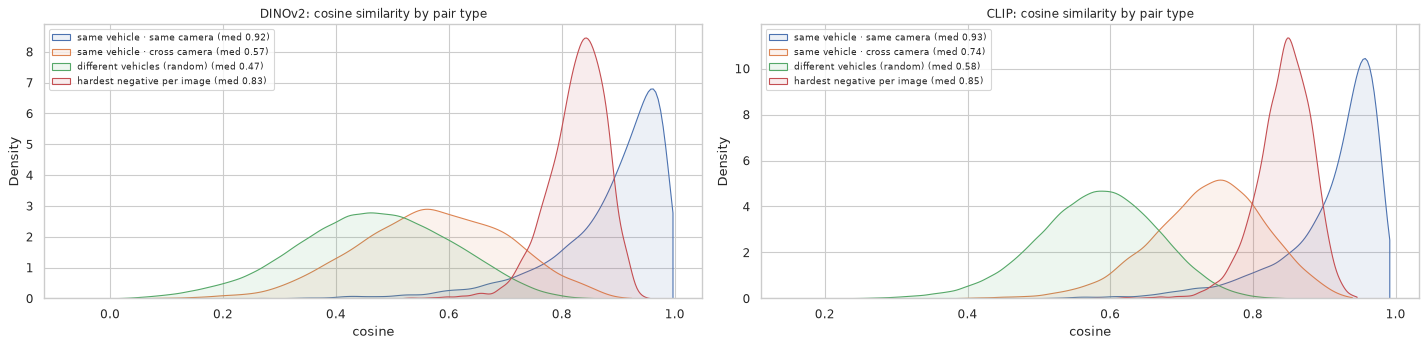

In [11]:
same_id = pid[:, None] == pid[None, :]
same_cam = cam[:, None] == cam[None, :]
upper = np.triu(np.ones_like(same_id), 1)
rng = np.random.default_rng(0)
neg_pairs = rng.integers(0, len(it), (400_000, 2))
neg_pairs = neg_pairs[pid[neg_pairs[:, 0]] != pid[neg_pairs[:, 1]]]


def pair_sims(E):
    S = E[it] @ E[it].T
    hard_neg = np.where(same_id, -1, S).max(1)
    xcam_pos = np.where(same_id & ~same_cam, S, np.nan)
    return S, {
        "same vehicle · same camera": S[upper & same_id & same_cam],
        "same vehicle · cross camera": S[upper & same_id & ~same_cam],
        "different vehicles (random)": S[neg_pairs[:, 0], neg_pairs[:, 1]],
        "hardest negative per image": hard_neg,
    }, np.nanmax(xcam_pos, 1), hard_neg


fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
S_dino = None
for (name, E), a in zip({"DINOv2": E_dino, "CLIP": E_clip}.items(), axes):
    S, d, best_pos, hard_neg = pair_sims(E)
    if name == "DINOv2":
        S_dino = S
    for k, v in d.items():
        sns.kdeplot(v, ax=a, label=f"{k} (med {np.median(v):.2f})", fill=True, alpha=0.1, cut=0)
    a.set(title=f"{name}: cosine similarity by pair type", xlabel="cosine")
    a.legend(fontsize=8)
    print(f"{name}: best cross-camera positive < hardest negative for {np.mean(best_pos < hard_neg):.1%} of train images "
          f"(zero-shot cross-camera Rank-1 ≈ {np.mean(best_pos > hard_neg):.1%})")
plt.tight_layout()
plt.show()

**Open-set sanity check.** If test vehicles leaked into train, the test→train nearest-neighbour similarity would be
shifted up compared with train→(nearest *other* vehicle) similarity.

                                                  median    q90    q99    max
DINOv2 train → nearest other-vehicle train image   0.833  0.885  0.918  0.984
       test → nearest train image                  0.832  0.887  0.926  0.949
CLIP   train → nearest other-vehicle train image   0.847  0.889  0.918  0.945
       test → nearest train image                  0.847  0.891  0.923  0.950


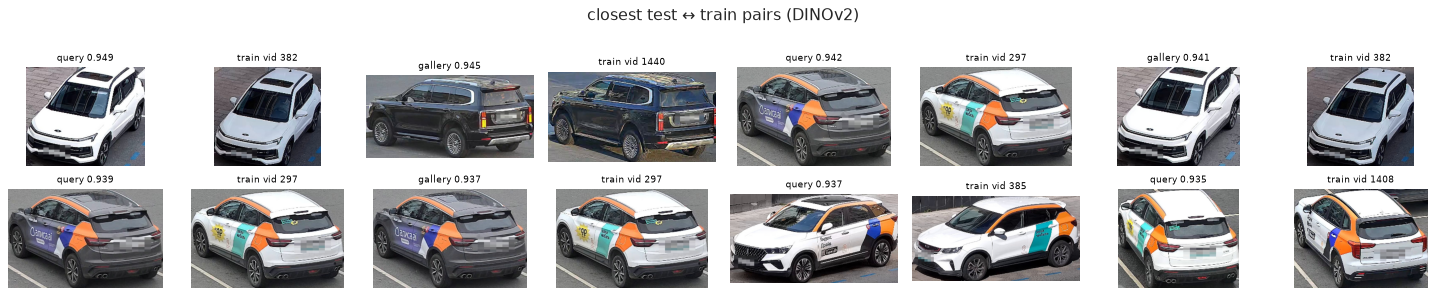

In [12]:
S_clip = E_clip[it] @ E_clip[it].T
nn = {}
for name, S_, E in [("DINOv2", S_dino, E_dino), ("CLIP", S_clip, E_clip)]:
    nn[(name, "train → nearest other-vehicle train image")] = np.where(same_id, -1, S_).max(1)
    nn[(name, "test → nearest train image")] = (E[te] @ E[it].T).max(1)
del S_clip
print(pd.DataFrame({k: np.quantile(v, [0.5, 0.9, 0.99, 1.0]) for k, v in nn.items()}, index=["median", "q90", "q99", "max"]).T.round(3))

S_tt = E_dino[te] @ E_dino[it].T
best_tt, arg_tt = S_tt.max(1), S_tt.argmax(1)
top = np.argsort(-best_tt)[:8]
show_crops([x for k in top for x in (te[k], it[arg_tt[k]])],
           titles=[t for k in top for t in (f"{M.split[te[k]]} {best_tt[k]:.3f}", f"train vid {pid[arg_tt[k]]}")],
           ncol=8, suptitle="closest test ↔ train pairs (DINOv2)")

**Findings.**
* Off-the-shelf features are **not identity-aware across cameras**. DINOv2 same-vehicle cross-camera pairs (median cos 0.57)
  sit barely above random pairs (0.47) and far below each image's hardest negative (0.83) → zero-shot cross-camera
  Rank-1 ≈ 4%. CLIP is better (0.74 vs 0.85, Rank-1 ≈ 16%): it encodes make/colour semantics, while DINOv2 CLS
  encodes viewpoint and scene.
* Bursts are near-duplicates (same vehicle · same camera: median 0.92–0.93). They inflate any metric that keeps
  same-camera matches and make training batches redundant.
* **The open-set guarantee holds:** test→train NN similarities are distributed exactly like train→other-vehicle NN
  (medians 0.832 vs 0.833 for DINOv2, 0.847 vs 0.847 for CLIP); the closest pairs are look-alikes, not the same car.

## 7. How was the test split built?

### 7a. Row order leaks identity
`train.csv` is sorted by vehicle (every `vehicle_id` is one contiguous block). If query and gallery are sorted the
same way, the nearest gallery item of query *i* sits near row *i × |G| / |Q|*.

train: 1541 contiguous vehicle blocks for 1541 vehicles


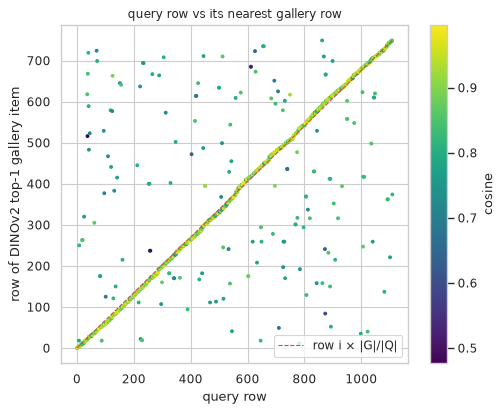

Spearman(query row, top-1 gallery row) = 0.847; top-1 within ±10 rows of the diagonal: 84.4%


In [13]:
blocks = (tr.vehicle_id != tr.vehicle_id.shift()).sum()
print(f"train: {blocks} contiguous vehicle blocks for {tr.vehicle_id.nunique()} vehicles")

S_qg = E_dino[qi] @ E_dino[gi].T
nn_g, nn_s = S_qg.argmax(1), S_qg.max(1)
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(np.arange(len(qi)), nn_g, c=nn_s, s=6, cmap="viridis")
ax.plot([0, len(qi)], [0, len(gi)], "r--", lw=1, label="row i × |G|/|Q|")
ax.set(xlabel="query row", ylabel="row of DINOv2 top-1 gallery item", title="query row vs its nearest gallery row")
plt.colorbar(sc, label="cosine")
ax.legend()
plt.show()
near_diag = np.abs(nn_g - np.arange(len(qi)) * len(gi) / len(qi)) < 10
print(f"Spearman(query row, top-1 gallery row) = {spearmanr(np.arange(len(qi)), nn_g)[0]:.3f}; "
      f"top-1 within ±10 rows of the diagonal: {near_diag.mean():.1%}")

### 7b. Hypothesis: gallery = one frame per (vehicle, camera), query = all other frames
Build a *pseudo-test* from train with that recipe (sampled down to ~300 vehicles to match the test size),
then compare its fingerprints with the real test.

In [14]:
BOX = M[["x", "y", "w", "h"]].to_numpy(np.float32)


def best_iou(a_idx, b_idx, chunk=512):
    out = np.empty(len(a_idx), np.float32)
    B = BOX[b_idx][None]
    for s in range(0, len(a_idx), chunk):
        A = BOX[a_idx[s: s + chunk]][:, None]
        iw = np.clip(np.minimum(A[..., 0] + A[..., 2], B[..., 0] + B[..., 2]) - np.maximum(A[..., 0], B[..., 0]), 0, None)
        ih = np.clip(np.minimum(A[..., 1] + A[..., 3], B[..., 1] + B[..., 3]) - np.maximum(A[..., 1], B[..., 1]), 0, None)
        inter = iw * ih
        out[s: s + chunk] = (inter / (A[..., 2] * A[..., 3] + B[..., 2] * B[..., 3] - inter)).max(1)
    return out


def make_pseudo_test(df, seed=0, n_vehicles=None):
    """Mirror of the inferred test recipe: gallery = one random frame per (vehicle, camera), query = the rest."""
    if n_vehicles:
        keep = np.random.default_rng(seed).choice(df.vehicle_id.unique(), n_vehicles, replace=False)
        df = df[df.vehicle_id.isin(keep)]
    gal = df.groupby(["vehicle_id", "camera_id"]).sample(1, random_state=seed).index
    return np.sort(df.index.difference(gal).to_numpy()), np.sort(gal.to_numpy())


def fingerprint(q_idx, g_idx):
    s = E_dino[q_idx] @ E_dino[g_idx].T
    consec = lambda idx: np.mean([best_iou(idx[k + 1: k + 2], idx[k: k + 1])[0] > 0.9 for k in range(len(idx) - 1)])
    return {
        "query / gallery": len(q_idx) / len(g_idx),
        "queries with a gallery box IoU > 0.9": np.mean(best_iou(q_idx, g_idx) > 0.9),
        "queries with top-1 gallery cos > 0.9": np.mean(s.max(1) > 0.9),
        "median top-1 gallery cos": np.median(s.max(1)),
        "consecutive query rows IoU > 0.9": consec(q_idx),
        "consecutive gallery rows IoU > 0.9": consec(g_idx),
    }


fp = pd.DataFrame({f"pseudo-test seed {s}": fingerprint(*make_pseudo_test(tr, s, 300)) for s in range(3)})
fp["real test"] = pd.Series(fingerprint(qi, gi))
fp

,pseudo-test seed 0,pseudo-test seed 1,pseudo-test seed 2,real test
query / gallery,1.453,1.489,1.441,1.480
queries with a gallery box IoU > 0.9,0.757,0.761,0.750,0.737
queries with top-1 gallery cos > 0.9,0.608,0.560,0.571,0.584
median top-1 gallery cos,0.921,0.912,0.916,0.919
consecutive query rows IoU > 0.9,0.143,0.157,0.154,0.170
consecutive gallery rows IoU > 0.9,0.000,0.003,0.001,0.000


**Findings.**
* **Row-order leak.** Query and gallery CSVs are sorted by vehicle: for 84% of queries the nearest gallery item lies
  within ±10 rows of *i·|G|/|Q|* (Spearman 0.85). Never use row position — it won't survive the hidden test, and
  `embeddings.npy` is checked precisely to catch hand-made rankings. Shuffle rows in local validation.
* **The test recipe is reverse-engineered.** A pseudo-test built as *gallery = one random frame per (vehicle, camera),
  query = the remaining frames* reproduces every fingerprint of the real test: query/gallery 1.44–1.49 vs 1.48;
  75–76% vs 74% of queries with a gallery box IoU > 0.9; median top-1 cos 0.91–0.92 vs 0.92; consecutive gallery rows
  never overlap.
* Consequences: (1) almost every query has its **burst sibling from the same camera** in the gallery — a trivial top-1
  that the metric discards as junk; (2) all real matches are cross-camera, and for 2/3 of vehicles there is exactly one;
  (3) every public query has a match, so **TNR cannot be measured on the public test** — the refusal threshold has to
  be calibrated on simulated distractors (Section 11).

## 8. Scenes & camera bias

Cameras are static, so the frame *with the vehicle masked out* identifies the camera. Two questions:
(a) are test frames shot by the same cameras as train? (b) how much camera information leaks into a
*vehicle* crop embedding (background, viewpoint, colour cast)?

1-NN camera accuracy (other vehicles only): scene emb 93.1% · vehicle crop emb 49.8% · chance 3.4%


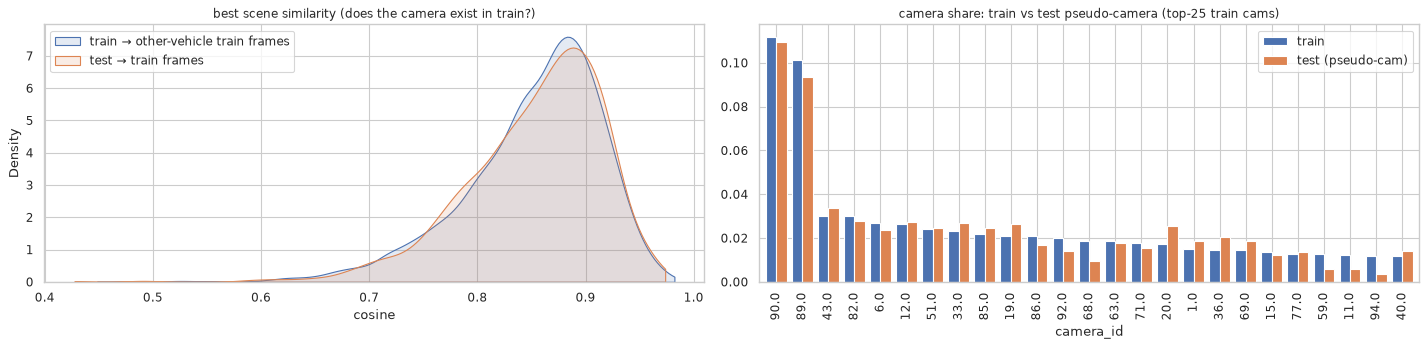

distinct pseudo-cams in test: 92 · query and its top-1 gallery item share a pseudo-cam: 81.8%


In [15]:
Ssc = E_scene[it] @ E_scene[it].T
Ssc_other = np.where(same_id, -1, Ssc)  # ignore a vehicle's own frames (trivially same scene)
scene_nn_acc = (cam[Ssc_other.argmax(1)] == cam).mean()
crop_nn_acc = (cam[np.where(same_id, -1, S_dino).argmax(1)] == cam).mean()
chance = ((per_cam.n_img / len(tr)) ** 2).sum()
print(f"1-NN camera accuracy (other vehicles only): scene emb {scene_nn_acc:.1%} · vehicle crop emb {crop_nn_acc:.1%} · chance {chance:.1%}")

S_te_sc = E_scene[te] @ E_scene[it].T
best_te_sc = S_te_sc.max(1)
M["pseudo_cam"] = -1
M.loc[te, "pseudo_cam"] = cam[S_te_sc.argmax(1)]
M.loc[it, "pseudo_cam"] = cam

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
sns.kdeplot(Ssc_other.max(1), ax=ax[0], label="train → other-vehicle train frames", fill=True, alpha=0.15, cut=0)
sns.kdeplot(best_te_sc, ax=ax[0], label="test → train frames", fill=True, alpha=0.15, cut=0)
ax[0].set(title="best scene similarity (does the camera exist in train?)", xlabel="cosine")
ax[0].legend()
share = pd.DataFrame({"train": tr.camera_id.value_counts(normalize=True),
                      "test (pseudo-cam)": M.loc[te, "pseudo_cam"].value_counts(normalize=True)}).fillna(0)
share.sort_values("train", ascending=False).head(25).plot.bar(ax=ax[1], width=0.8)
ax[1].set(title="camera share: train vs test pseudo-camera (top-25 train cams)", xlabel="camera_id")
plt.tight_layout()
plt.show()
print(f"distinct pseudo-cams in test: {M.loc[te, 'pseudo_cam'].nunique()} · "
      f"query and its top-1 gallery item share a pseudo-cam: {(M.pseudo_cam.to_numpy()[qi] == M.pseudo_cam.to_numpy()[gi[nn_g]]).mean():.1%}")

**Findings.**
* The masked scene identifies the camera: 1-NN camera accuracy 93% (chance 3.4%). Test scenes match train scenes as
  well as train matches itself, and 92 of 96 cameras re-appear in test with the same shares →
  **the test is shot by the same camera network; only the vehicles are new.**
* **Camera bias in vehicle features.** A DINOv2 *crop* embedding retrieves a different vehicle from the same camera 50% of
  the time (chance 3.4%): background, viewpoint and colour cast dominate raw features. It shows in the failure cases
  (Section 10): the top-5 for a camera-90 query are all camera-90 cars.
* → Train with cross-camera positives and same-camera hard negatives; try camera-aware tricks (camera-wise BN,
  camera-mean subtraction gives +22–32% relative mAP even zero-shot, Section 10). Pseudo camera ids for test are
  cheap and reliable, but using them at inference is a grey area under the ТЗ — ask before relying on it.

## 9. Vehicle attributes (CLIP zero-shot)

Noisy labels, but good enough to see the mix (colour, body, viewpoint, taxi/carsharing liveries) and where the hard cases are.

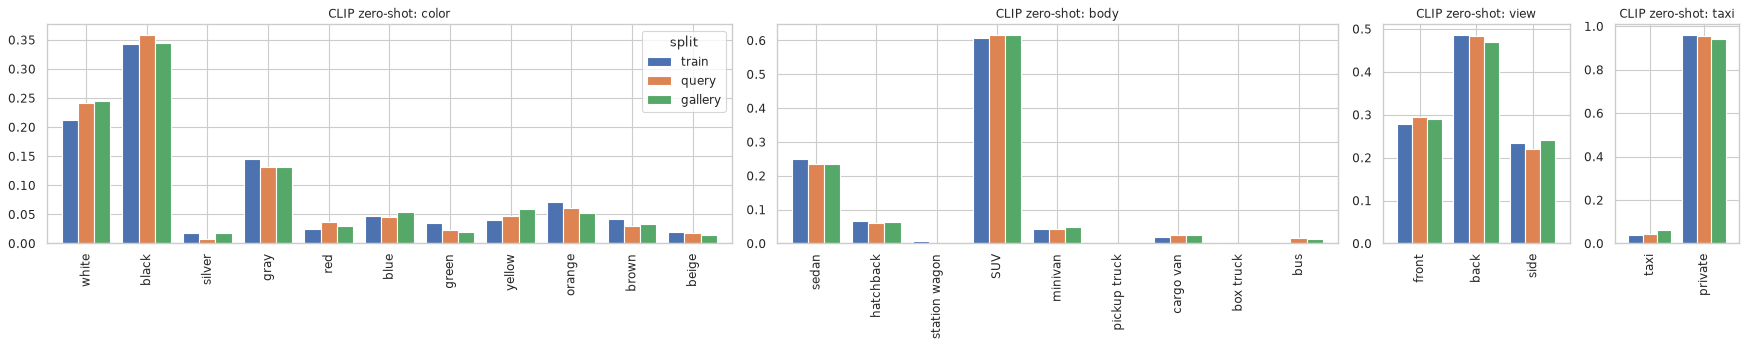

colour label agreement inside a (vehicle, camera) burst: 90.8% (rough zero-shot label noise gauge)


In [16]:
T = np.load(CACHE / "clip_text.npz")
LABELS = json.loads((CACHE / "clip_text_labels.json").read_text())
for k, labs in LABELS.items():
    logits = 100 * E_clip @ T[k].T
    p = np.exp(logits - logits.max(1, keepdims=True))
    p /= p.sum(1, keepdims=True)
    M[k] = pd.Categorical(np.array(labs)[p.argmax(1)], categories=labs)
    M[f"{k}_conf"] = p.max(1)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5), gridspec_kw={"width_ratios": [11, 9, 3, 2]})
for k, a in zip(LABELS, axes):
    pd.crosstab(M[k], M.split, normalize="columns")[SPLITS].plot.bar(ax=a, color=[PAL[s] for s in SPLITS], width=0.8, legend=k == "color")
    a.set(title=f"CLIP zero-shot: {k}", xlabel="")
plt.tight_layout()
plt.show()

tr = M.iloc[it]  # refresh with attribute columns
purity = tr.groupby(["vehicle_id", "camera_id"]).color.agg(lambda s: s.value_counts(normalize=True).iloc[0]).mean()
print(f"colour label agreement inside a (vehicle, camera) burst: {purity:.1%} (rough zero-shot label noise gauge)")

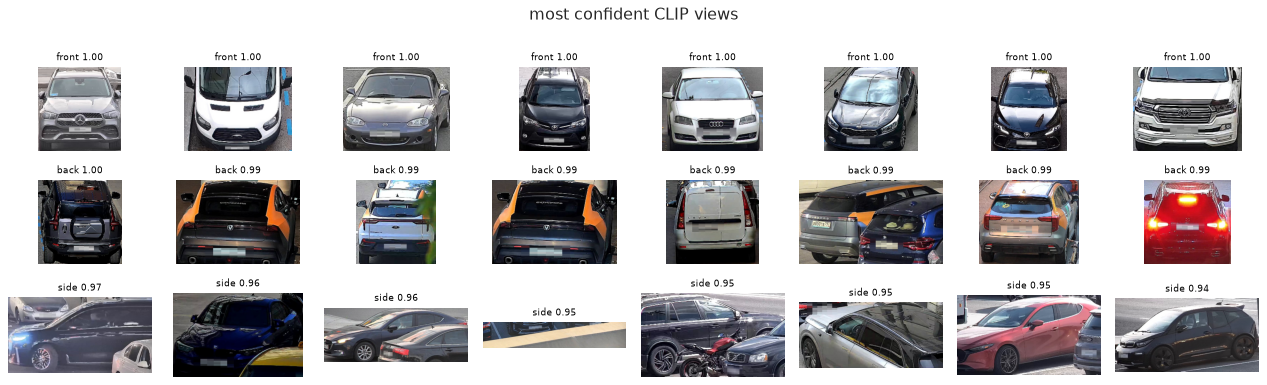

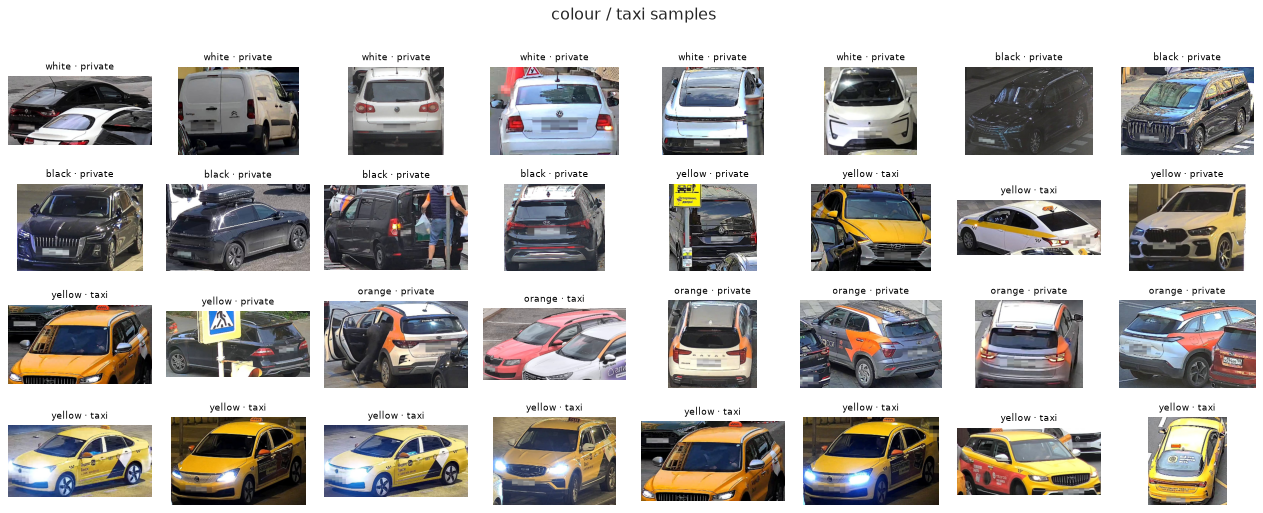

In [17]:
view_idx = [i for v in LABELS["view"] for i in M[M.view == v].nlargest(8, "view_conf").index]
show_crops(view_idx, titles=[f"{M.view[i]} {M.view_conf[i]:.2f}" for i in view_idx], suptitle="most confident CLIP views", size=2.0)
col_idx = [i for c in ["white", "black", "yellow", "orange"]
           for i in M[M.color == c].sample(min(6, (M.color == c).sum()), random_state=0).index] + \
          list(M[M.taxi == "taxi"].nlargest(8, "taxi_conf").index)
show_crops(col_idx, titles=[f"{M.color[i]} · {M.taxi[i]}" for i in col_idx], ncol=8, size=2.0, suptitle="colour / taxi samples")

**Viewpoint change across cameras** — the core difficulty of cross-camera ReID. Majority view per (vehicle, camera),
then all cross-camera pairs of the same vehicle:

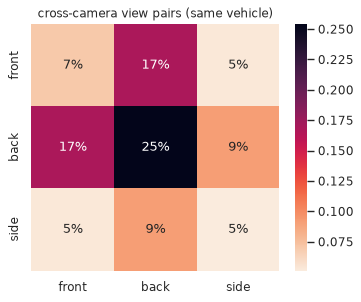

vehicles seen from the front in one camera and from the back in another: 46.5%


In [18]:
vc = tr.groupby(["vehicle_id", "camera_id"]).view.agg(lambda s: s.value_counts().index[0]).reset_index()
vp = [tuple(sorted((a, b))) for _, grp in vc.groupby("vehicle_id") for a, b in combinations(grp.view.astype(str), 2)]
vp = pd.Series(vp).value_counts(normalize=True)
mat = pd.DataFrame(0.0, index=LABELS["view"], columns=LABELS["view"])
for (a, b), v in vp.items():
    mat.loc[a, b] += v / 2
    mat.loc[b, a] += v / 2
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(mat, annot=True, fmt=".0%", cmap="rocket_r", ax=ax)
ax.set_title("cross-camera view pairs (same vehicle)")
plt.show()
no_overlap = vc.groupby("vehicle_id").view.agg(lambda s: {"front", "back"} <= set(s.astype(str)))
print(f"vehicles seen from the front in one camera and from the back in another: {no_overlap.mean():.1%}")

**Findings.**
* Colour is a weak cue: ~70% of vehicles are black / white / grey and ~61% are SUVs (CLIP zero-shot; 91% label agreement
  inside bursts, so the labels are roughly right). The attribute mix is identical across splits.
* 4–6% taxis, plus orange / blue / yellow **carsharing fleets**: same make and livery → the hardest negatives, and exactly
  where the refusal mode must say "not sure".
* **Viewpoint is the core difficulty:** 48% of crops are rear views, 34% of cross-camera same-vehicle pairs are
  front↔back, and 46.5% of vehicles are seen from the front in one camera and from the back in another. Identity has to
  be carried by view-independent cues (silhouette, roof, wheels, colour, stickers, damage).

## 10. Zero-shot retrieval baseline & error analysis

Market-1501-style protocol, as in the ТЗ: a gallery item with the **same vehicle and same camera** as the query is
*junk* (ignored); other same-camera items still count as negatives. Two set-ups:
* **all-vs-all** over train;
* **pseudo-test** (Section 7b recipe, all 1541 vehicles): query vs gallery, closest to the real evaluation.

In [19]:
def reid_eval(sim, q_pid, q_cam, g_pid, g_cam, chunk=1024, topk_junk=10):
    ap, r1, r5, inp, junk10 = [], [], [], [], []
    for s in range(0, len(q_pid), chunk):
        S = sim[s: s + chunk]
        order = np.argsort(-S, axis=1)
        match = g_pid[order] == q_pid[s: s + chunk, None]
        junk = match & (g_cam[order] == q_cam[s: s + chunk, None])
        good, valid = match & ~junk, ~junk
        cv_, cg = np.cumsum(valid, 1), np.cumsum(good, 1)
        npos = good.sum(1)
        rows = np.arange(len(S))
        first = cv_[rows, good.argmax(1)]
        last = cv_[rows, good.shape[1] - 1 - good[:, ::-1].argmax(1)]
        ok = npos > 0
        ap.append((np.where(good, cg / np.maximum(cv_, 1), 0).sum(1) / np.maximum(npos, 1))[ok])
        r1.append(first[ok] <= 1)
        r5.append(first[ok] <= 5)
        inp.append((npos / last)[ok])
        junk10.append(junk[:, :topk_junk].sum(1)[ok])
    ap, r1, r5, inp, junk10 = map(np.concatenate, (ap, r1, r5, inp, junk10))
    return {"mAP": ap.mean(), "R1": r1.mean(), "R5": r5.mean(), "mINP": inp.mean(), "junk in top-10": junk10.mean()}, ap


def cam_debias(E, cams, k=20):
    """Subtract a shrunk per-camera mean embedding (uses TRUE camera ids -> analysis only)."""
    out = E.copy()
    for c in np.unique(cams):
        m = cams == c
        out[m] -= E[m].mean(0) * m.sum() / (m.sum() + k)
    return l2n(out)


EMB = {
    "DINOv2": E_dino[it],
    "CLIP": E_clip[it],
    "DINOv2 ⊕ CLIP": l2n(np.hstack([E_dino[it], E_clip[it]])),
    "DINOv2 − camera mean": cam_debias(E_dino[it], cam),
}
pq, pg = make_pseudo_test(tr, seed=0)
res, ap_pseudo = {}, {}
for name, E in EMB.items():
    res[(name, "all-vs-all")], _ = reid_eval(E @ E.T, pid, cam, pid, cam)
    res[(name, "pseudo-test")], ap_pseudo[name] = reid_eval(E[pq] @ E[pg].T, pid[pq], cam[pq], pid[pg], cam[pg])
pd.DataFrame(res).T

mAP     R1     R5   mINP  junk in top-10
DINOv2               all-vs-all   0.036  0.040  0.070  0.020           2.444
                     pseudo-test  0.041  0.035  0.066  0.030           0.889
CLIP                 all-vs-all   0.146  0.161  0.281  0.082           2.514
                     pseudo-test  0.165  0.136  0.276  0.127           0.925
DINOv2 ⊕ CLIP        all-vs-all   0.090  0.105  0.177  0.050           2.540
                     pseudo-test  0.101  0.088  0.172  0.074           0.937
DINOv2 − camera mean all-vs-all   0.044  0.045  0.093  0.023           2.441
                     pseudo-test  0.054  0.041  0.094  0.039           0.884

**What makes a query hard?** Per-query AP (DINOv2, pseudo-test) against query properties.

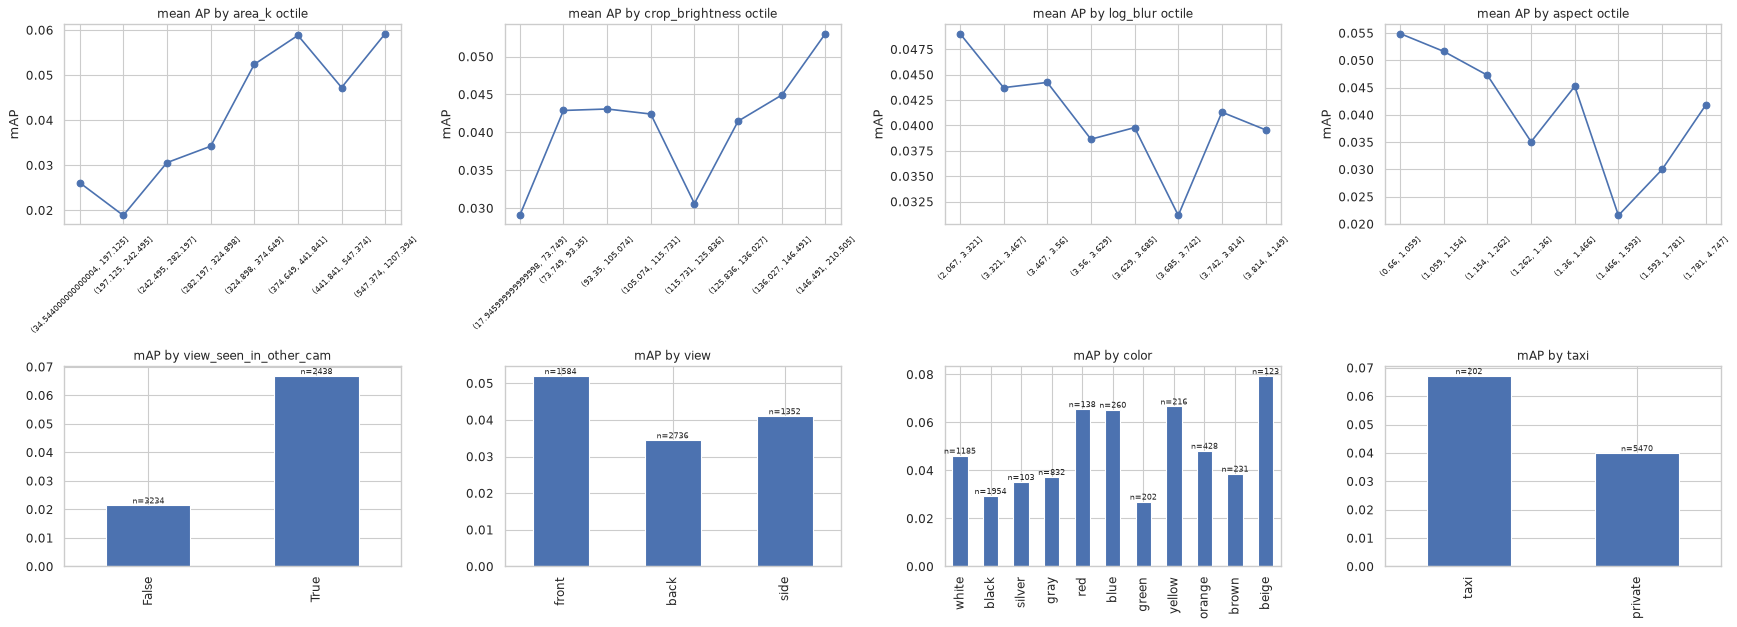

In [20]:
Qd = tr.iloc[pq].copy()
Qd["AP"] = ap_pseudo["DINOv2"]
gal_views = tr.iloc[pg].groupby("vehicle_id").apply(lambda d: d[["camera_id", "view"]].values.tolist())
Qd["view_seen_in_other_cam"] = [any(v == row.view and c != row.camera_id for c, v in gal_views[row.vehicle_id])
                                for row in Qd.itertuples()]

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for c, a in zip(["area_k", "crop_brightness", "log_blur", "aspect"], axes[0]):
    Qd.groupby(pd.qcut(Qd[c], 8, duplicates="drop"), observed=True).AP.mean().plot(ax=a, marker="o")
    a.set(title=f"mean AP by {c} octile", xlabel="", ylabel="mAP")
    a.tick_params(axis="x", rotation=45, labelsize=7)
for c, a in zip(["view_seen_in_other_cam", "view", "color", "taxi"], axes[1]):
    agg = Qd.groupby(c, observed=True).AP.agg(["mean", "size"])
    agg["mean"].plot.bar(ax=a)
    a.set(title=f"mAP by {c}", xlabel="")
    for k, (m_, n_) in enumerate(agg.values):
        a.text(k, m_, f"n={int(n_)}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

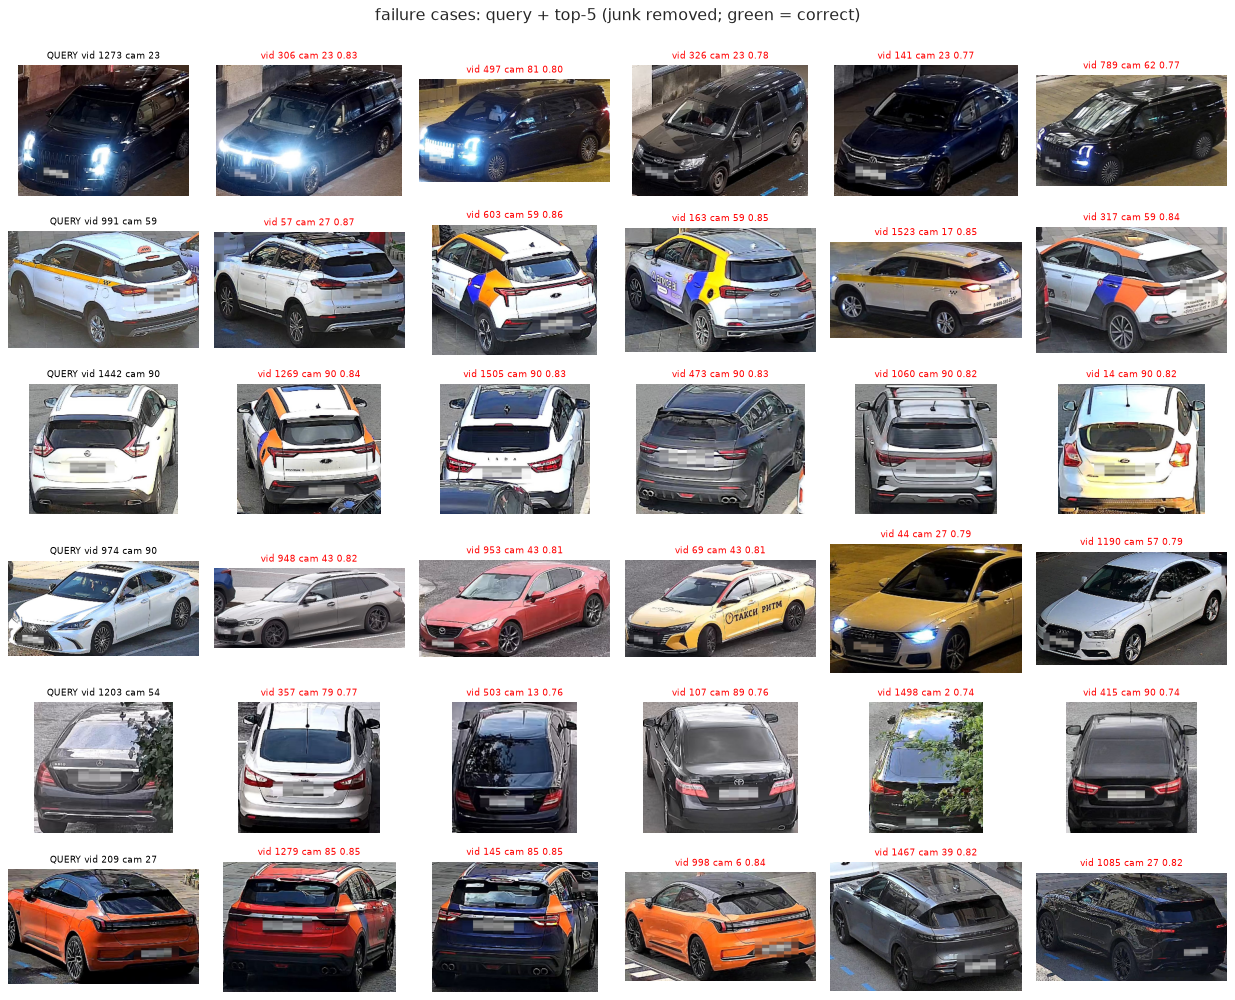

In [21]:
Sd = EMB["DINOv2"][pq] @ EMB["DINOv2"][pg].T
junk_mask = (pid[pq][:, None] == pid[pg][None]) & (cam[pq][:, None] == cam[pg][None])
Sd_nojunk = np.where(junk_mask, -np.inf, Sd)
worst = rng.choice(np.flatnonzero(ap_pseudo["DINOv2"] < 0.05), 6, replace=False)
idx, titles, colors = [], [], []
for k in worst:
    top5 = np.argsort(-Sd_nojunk[k])[:5]
    idx += [pq[k]] + list(pg[top5])
    titles += [f"QUERY vid {pid[pq[k]]} cam {cam[pq[k]]}"] + [f"vid {pid[pg[j]]} cam {cam[pg[j]]} {Sd[k, j]:.2f}" for j in top5]
    colors += ["black"] + ["green" if pid[pg[j]] == pid[pq[k]] else "red" for j in top5]
show_crops(idx, titles, colors, ncol=6, size=2.6, suptitle="failure cases: query + top-5 (junk removed; green = correct)")

**Findings.**
* Zero-shot baselines on the pseudo-test: DINOv2 mAP 0.04, CLIP 0.17, DINOv2 ⊕ CLIP 0.10 (the concat is dragged down by
  DINOv2), DINOv2 − camera mean 0.05. All-vs-all and pseudo-test agree → the pseudo-test is a stable protocol.
  **A fine-tuned ReID model is mandatory**; CLIP-like backbones look like the better starting point.
* About 0.9 of the top-10 slots per query are taken by same-camera junk (the burst sibling). If the organisers compute mAP
  from the submitted top-10 lists, that slot is wasted — clarify how the reference script handles it.
* Hard queries: the vehicle is never seen from the query's viewpoint in another camera (mAP 0.02 vs 0.07), small crops
  (bottom quarter 2–3× worse), black / grey / green cars. Taxis and liveried cars are easier than plain private cars.
* Failure cases are look-alikes of the same model and livery (carsharing crossovers, white taxis) and same-camera cars
  with the same pose and background.

## 11. Refusal-mode simulation

Pseudo-test again, but the gallery frames of a random 30% of vehicles are removed, so their queries have
**no match** (these are the negatives TNR is computed on). Junk (same vehicle + same camera) is removed before scoring.
Candidate confidence scores: raw top-1 cosine, and top-1 z-scored against the query's own similarity distribution.

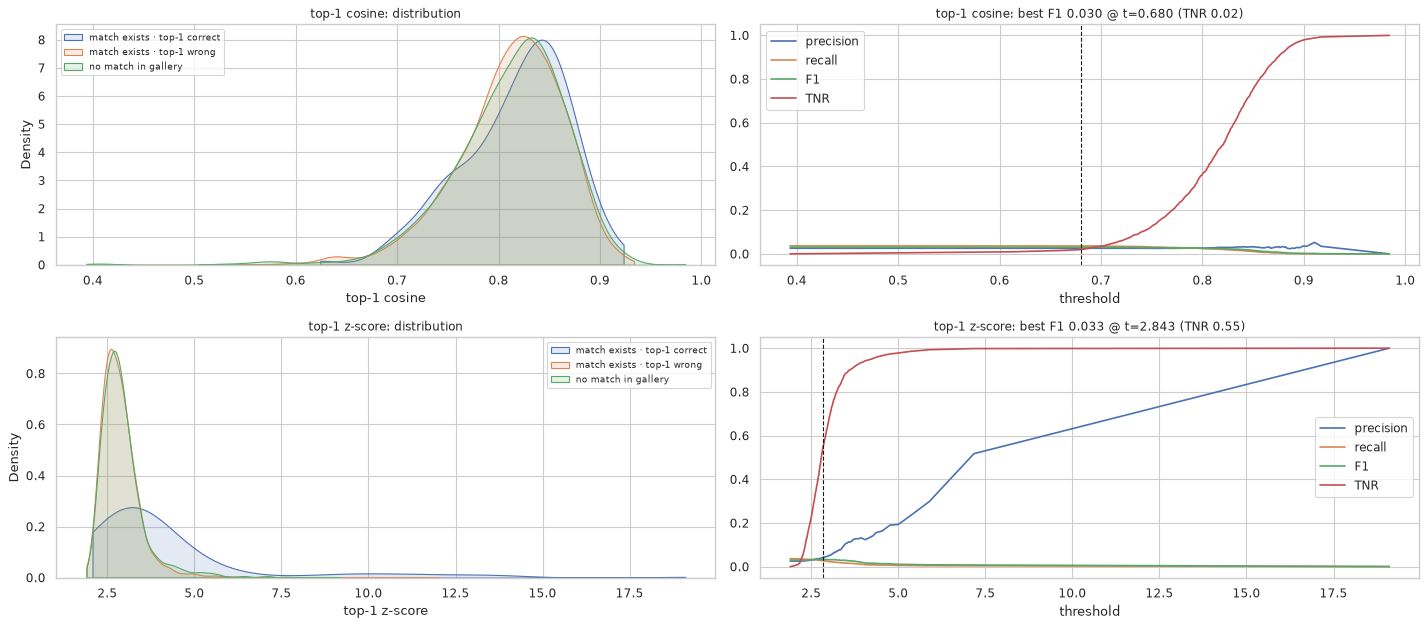

queries: 5672 · with a match: 69.9% · zero-shot top-1 correct among those: 3.7%


,PR-AUC (top-1 correct vs not),precision,recall,F1,TNR,t*
top-1 cosine,0.029,0.026,0.036,0.030,0.019,0.680
top-1 z-score,0.173,0.043,0.028,0.033,0.552,2.843


In [22]:
from sklearn.metrics import average_precision_score

drop = rng.choice(np.unique(pid), int(0.3 * len(np.unique(pid))), replace=False)
g_keep = pg[~np.isin(pid[pg], drop)]
S_r = EMB["DINOv2"][pq] @ EMB["DINOv2"][g_keep].T
S_r = np.where((pid[pq][:, None] == pid[g_keep][None]) & (cam[pq][:, None] == cam[g_keep][None]), np.nan, S_r)
top1 = np.nanargmax(S_r, 1)
s1 = np.nanmax(S_r, 1)
has_match = ~np.isin(pid[pq], drop)
correct = has_match & (pid[g_keep][top1] == pid[pq])
scores = {"top-1 cosine": s1, "top-1 z-score": (s1 - np.nanmean(S_r, 1)) / np.nanstd(S_r, 1)}


def refusal_curve(score):
    rows = []
    for t in np.quantile(score, np.linspace(0, 1, 201)):
        acc = score >= t
        prec = (acc & correct).sum() / max(acc.sum(), 1)
        rec = (acc & correct).sum() / has_match.sum()
        rows.append({"t": t, "precision": prec, "recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-9),
                     "TNR": (~acc & ~has_match).sum() / (~has_match).sum()})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(2, 2, figsize=(18, 8))
summary = {}
for (name, sc), (a0, a1) in zip(scores.items(), axes):
    for lab, m in {"match exists · top-1 correct": correct, "match exists · top-1 wrong": has_match & ~correct,
                   "no match in gallery": ~has_match}.items():
        sns.kdeplot(sc[m], ax=a0, label=lab, fill=True, alpha=0.15, cut=0)
    a0.set(title=f"{name}: distribution", xlabel=name)
    a0.legend(fontsize=8)
    cur = refusal_curve(sc)
    best = cur.loc[cur.F1.idxmax()]
    cur.plot(x="t", y=["precision", "recall", "F1", "TNR"], ax=a1)
    a1.axvline(best.t, color="k", ls="--", lw=1)
    a1.set(title=f"{name}: best F1 {best.F1:.3f} @ t={best.t:.3f} (TNR {best.TNR:.2f})", xlabel="threshold")
    summary[name] = {"PR-AUC (top-1 correct vs not)": average_precision_score(correct, sc), **best.drop("t").to_dict(), "t*": best.t}
plt.tight_layout()
plt.show()
print(f"queries: {len(pq)} · with a match: {has_match.mean():.1%} · zero-shot top-1 correct among those: {correct[has_match].mean():.1%}")
pd.DataFrame(summary).T

**Findings.**
* With zero-shot features only 3.7% of top-1 answers are correct, so the absolute F1 / TNR here mean nothing — the value
  is in the *method*.
* **Raw top-1 cosine carries no information about correctness:** PR-AUC 0.029 ≈ the positive rate (0.026); correct, wrong
  and no-match queries have the same cosine distribution. A **per-query z-score** of the top-1 against the query's own
  similarity distribution is 6× better (PR-AUC 0.17): correct matches form a long right tail.
* → Calibrate refusal on the pseudo-test with simulated distractors, using a normalised score (z-score, top-1 − top-2
  margin, or k-reciprocal re-ranking distance). Pick the threshold that maximises F1 under a TNR floor, re-tune it after
  every model change, and show this curve at the defence.

## 12. Takeaways

**Validation — mirror the test exactly**
1. Hold out vehicles (GroupKFold on `vehicle_id`, ~300 vehicles per fold ≈ public test). Inside the hold-out build the
   pseudo-test with `make_pseudo_test`: gallery = 1 frame per (vehicle, camera), query = the rest. Shuffle rows.
2. Score with `reid_eval` (mAP / R1 / R5 / mINP, same-vehicle-same-camera junk removed). The pseudo-test reproduces the
   real test's fingerprints (7b) and there is no train↔test shift (5, 8), so local CV should track the hidden score.
3. For the refusal mode, drop the gallery of ~30% of hold-out vehicles and tune F1 / TNR on a normalised score (11).

**Modelling**
4. Off-the-shelf features fail (pseudo-test R1 4–14%): fine-tune a ReID model (ID loss + triplet / circle loss,
   PK sampling with cross-camera positives). Start from CLIP-like or strong supervised backbones rather than raw DINOv2 CLS.
   The 2 GB weights limit allows ViT-B / ConvNeXt-B class models, but speed is 20% of the score — watch batch-1 latency.
5. Fight camera bias (8): positives from other cameras, down-weight the dominant camera pair 89/90 (21% of data),
   try camera-wise BN / camera-mean subtraction.
6. Viewpoint is the main failure mode (46.5% of vehicles front ↔ back): flip / crop / random-erasing augmentations,
   a landscape input (w/h ≈ 1.35), part- or attention-based heads, k-reciprocal re-ranking over the gallery.
7. Treat a (vehicle, camera) burst as one view when sampling — the extra frames are near-duplicates.
8. Night and very low quality are < 1% of the data: augmentation is enough.

**Risks & questions for the organisers**
* `camera_id` is present in `train.csv` although the ТЗ says it is withheld — confirm it can be used for training.
* Is it allowed to use *inferred* camera ids (scene embedding, 93% accurate) at inference time?
* How does the reference script compute mAP from a top-10 submission when the same-camera burst sibling takes a slot?
* Don't exploit the row-order leak or the 11 duplicated frames (1 train ↔ gallery); mention them at the defence as found issues.